<a href="https://colab.research.google.com/github/AnishaP3/AnishaP3/blob/main/Notebooks/Project_Milestone_6_Final_Experiments_and_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#
---
#<center>**Reducing Inventory Waste in Grocery Stores**<center/>     
##### <center>**Anisha Penikalapati | Kritika Rajpal | Mary Penta Reddy | Suha Fasih | Zawwar Rizvi**<center/>

---

## **<ins>Data Pipeline</ins>**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [ ]:
# Load data
url = "https://drive.google.com/uc?export=download&id=1mtKaQBoUcGrpH2ppFvM6JPbYfzYeu_4E"
df = pd.read_csv(url)

#### **Dataset Filtering and Cleaning**

In [ ]:
# Removed ID Columns & Unnecessary Date Columns
df = df.drop(columns=['record_id', 'product_id', 'store_id', 'supplier_id', 'day_of_week', 'is_weekend', 'month'])

These columns do not contribute to prediction and were not needed for modeling.

In [ ]:
df

,product_name,category,region,transaction_date,expiration_date,shelf_life_days,days_remaining_at_purchase,storage_temp,temp_deviation,base_price,...,selling_price,units_sold,units_wasted,waste_pct,revenue,waste_cost,profit,profit_margin_pct,supplier_score,is_promoted
0,Donuts,Bakery,West,2024-09-25,2024-09-29,4,4,21.0,1.0,2.60,...,2.60,138,20,12.7,358.80,24.40,166.04,46.3,9,0
1,Sausages,Meat,Southwest,2023-04-14,2023-04-21,9,7,0.7,0.3,8.25,...,8.25,251,102,28.9,2070.75,426.36,595.21,28.7,6,0
2,Bagels,Bakery,Midwest,2024-10-25,2024-10-27,2,2,21.3,1.3,4.12,...,1.28,483,0,0.0,618.24,0.00,-405.72,-65.6,9,0
3,Vaccines,Pharmaceuticals,Midwest,2023-11-29,2024-02-17,87,80,8.0,3.0,209.56,...,209.56,477,0,0.0,99960.12,0.00,57988.89,58.0,6,0
4,Fresh Pasta,Ready_to_Eat,West,2023-08-06,2023-08-09,4,3,3.5,0.5,6.86,...,5.28,391,0,0.0,2064.48,0.00,879.75,42.6,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Dips,Deli,Southwest,2024-12-22,2024-12-27,5,5,3.5,0.5,12.10,...,12.10,149,0,0.0,1802.90,0.00,1063.86,59.0,10,0
99996,Frozen Dinners,Frozen_Meals,Midwest,2023-11-28,2024-06-06,204,191,-21.1,1.1,13.60,...,13.60,0,212,100.0,0.00,1392.84,-1392.84,0.0,8,0
99997,Chicken,Meat,Southwest,2023-06-15,2023-06-21,9,6,1.8,0.8,12.28,...,12.28,264,208,44.1,3241.92,1312.48,263.60,8.1,10,1
99998,Eye Drops,Pharmaceuticals,West,2024-12-14,2026-03-03,581,444,4.6,0.4,320.12,...,320.12,0,251,100.0,0.00,51919.35,-51919.35,0.0,6,0


In [ ]:
# Changing the transaction dates and expiration dates from strings to DateTime

from datetime import datetime
date_format = "%Y-%m-%d"
df['transaction_date'] = pd.to_datetime(df['transaction_date'])
df['expiration_date'] = pd.to_datetime(df['expiration_date'])
df.dtypes

,0
product_name,object
category,object
region,object
transaction_date,datetime64[ns]
expiration_date,datetime64[ns]
shelf_life_days,int64
days_remaining_at_purchase,int64
storage_temp,float64
temp_deviation,float64
base_price,float64


- These columns were converted from strings to datetime format so that it can be easier to sort and split the data into train/validate/test sections based on time.

In [ ]:
# Converting is_promoted type to boolean so that it is easier to read
df['is_promoted'] = df['is_promoted'].astype('bool')
df

,product_name,category,region,transaction_date,expiration_date,shelf_life_days,days_remaining_at_purchase,storage_temp,temp_deviation,base_price,...,selling_price,units_sold,units_wasted,waste_pct,revenue,waste_cost,profit,profit_margin_pct,supplier_score,is_promoted
0,Donuts,Bakery,West,2024-09-25,2024-09-29,4,4,21.0,1.0,2.60,...,2.60,138,20,12.7,358.80,24.40,166.04,46.3,9,False
1,Sausages,Meat,Southwest,2023-04-14,2023-04-21,9,7,0.7,0.3,8.25,...,8.25,251,102,28.9,2070.75,426.36,595.21,28.7,6,False
2,Bagels,Bakery,Midwest,2024-10-25,2024-10-27,2,2,21.3,1.3,4.12,...,1.28,483,0,0.0,618.24,0.00,-405.72,-65.6,9,False
3,Vaccines,Pharmaceuticals,Midwest,2023-11-29,2024-02-17,87,80,8.0,3.0,209.56,...,209.56,477,0,0.0,99960.12,0.00,57988.89,58.0,6,False
4,Fresh Pasta,Ready_to_Eat,West,2023-08-06,2023-08-09,4,3,3.5,0.5,6.86,...,5.28,391,0,0.0,2064.48,0.00,879.75,42.6,6,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Dips,Deli,Southwest,2024-12-22,2024-12-27,5,5,3.5,0.5,12.10,...,12.10,149,0,0.0,1802.90,0.00,1063.86,59.0,10,False
99996,Frozen Dinners,Frozen_Meals,Midwest,2023-11-28,2024-06-06,204,191,-21.1,1.1,13.60,...,13.60,0,212,100.0,0.00,1392.84,-1392.84,0.0,8,False
99997,Chicken,Meat,Southwest,2023-06-15,2023-06-21,9,6,1.8,0.8,12.28,...,12.28,264,208,44.1,3241.92,1312.48,263.60,8.1,10,True
99998,Eye Drops,Pharmaceuticals,West,2024-12-14,2026-03-03,581,444,4.6,0.4,320.12,...,320.12,0,251,100.0,0.00,51919.35,-51919.35,0.0,6,False


#### **Dataset Pre-processing**

##### **Data Leakage Check**

In [ ]:
# Leakage check — class means for all suspected columns
# ratio ~ 1.0 means safe; ratio > 5 or < 0.2 means leakage
print(f"{'column':25s} {'class0':>10s} {'class1':>10s} {'ratio':>8s}")
print("-" * 55)
for col in ['units_wasted', 'waste_pct', 'waste_cost', 'profit',
            'revenue', 'profit_margin_pct', 'units_sold',
            'spoilage_risk', 'selling_price', 'markdown_applied',
            'discount_pct', 'days_until_expiry', 'distribution_hours']:
    means = df.groupby('was_spoiled')[col].mean()
    ratio = means[1] / max(means[0], 1e-9)
    print(f"{col:25s} {means[0]:10.3f} {means[1]:10.3f} {ratio:8.2f}")

column                        class0     class1    ratio
-------------------------------------------------------
units_wasted                  42.303     92.262     2.18
waste_pct                     18.865     38.033     2.02
waste_cost                  1431.383   2464.519     1.72
profit                      1121.003   -541.201    -0.48
revenue                     6184.615   4780.091     0.77
profit_margin_pct             17.683     -4.375    -0.25
units_sold                   212.760    161.716     0.76
spoilage_risk                  0.192      0.209     1.09
selling_price                 34.002     35.825     1.05
markdown_applied               0.293      0.361     1.23
discount_pct                   0.097      0.118     1.22
days_until_expiry             54.879     53.830     0.98
distribution_hours            37.744     39.169     1.04


##### **Removing Features that could Leak Data**

In [ ]:
# Removed Columns that could Leak Data and reveal information that would not be available before spoilage occurs
df = df.drop(columns=['units_wasted', 'waste_pct', 'waste_cost', 'profit', 'revenue', 'profit_margin_pct', 'spoilage_risk', 'units_sold', 'selling_price', 'markdown_applied', 'discount_pct','days_until_expiry', 'expiration_date'])
df

,product_name,category,region,transaction_date,shelf_life_days,days_remaining_at_purchase,storage_temp,temp_deviation,base_price,cost_price,...,daily_demand,demand_variability,temp_abuse_events,distribution_hours,handling_score,packaging_score,was_spoiled,quality_grade,supplier_score,is_promoted
0,Donuts,Bakery,West,2024-09-25,4,4,21.0,1.0,2.60,1.22,...,54,0.35,0,41.5,9,10,0,A,9,False
1,Sausages,Meat,Southwest,2023-04-14,9,7,0.7,0.3,8.25,4.18,...,55,0.35,0,38.7,8,8,0,A,6,False
2,Bagels,Bakery,Midwest,2024-10-25,2,2,21.3,1.3,4.12,2.12,...,331,0.35,0,54.1,4,8,0,B,9,False
3,Vaccines,Pharmaceuticals,Midwest,2023-11-29,87,80,8.0,3.0,209.56,87.99,...,7,0.38,0,70.1,5,9,0,B,6,False
4,Fresh Pasta,Ready_to_Eat,West,2023-08-06,4,3,3.5,0.5,6.86,3.03,...,169,0.25,0,64.9,5,6,0,C,6,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Dips,Deli,Southwest,2024-12-22,5,5,3.5,0.5,12.10,4.96,...,53,0.18,1,34.3,10,10,0,A,10,False
99996,Frozen Dinners,Frozen_Meals,Midwest,2023-11-28,204,191,-21.1,1.1,13.60,6.57,...,0,0.46,0,55.8,6,7,1,B,8,False
99997,Chicken,Meat,Southwest,2023-06-15,9,6,1.8,0.8,12.28,6.31,...,65,0.21,0,52.3,6,7,0,B,10,True
99998,Eye Drops,Pharmaceuticals,West,2024-12-14,581,444,4.6,0.4,320.12,206.85,...,0,0.29,0,11.4,8,9,0,A,6,False


##### **Removing Irrelevant Features**

In [ ]:
# Removed irrelevant column that does not help predict spoilage
df = df.drop(columns=['distribution_hours'])
df

,product_name,category,region,transaction_date,shelf_life_days,days_remaining_at_purchase,storage_temp,temp_deviation,base_price,cost_price,...,spoilage_sensitivity,daily_demand,demand_variability,temp_abuse_events,handling_score,packaging_score,was_spoiled,quality_grade,supplier_score,is_promoted
0,Donuts,Bakery,West,2024-09-25,4,4,21.0,1.0,2.60,1.22,...,0.50,54,0.35,0,9,10,0,A,9,False
1,Sausages,Meat,Southwest,2023-04-14,9,7,0.7,0.3,8.25,4.18,...,0.90,55,0.35,0,8,8,0,A,6,False
2,Bagels,Bakery,Midwest,2024-10-25,2,2,21.3,1.3,4.12,2.12,...,0.50,331,0.35,0,4,8,0,B,9,False
3,Vaccines,Pharmaceuticals,Midwest,2023-11-29,87,80,8.0,3.0,209.56,87.99,...,0.85,7,0.38,0,5,9,0,B,6,False
4,Fresh Pasta,Ready_to_Eat,West,2023-08-06,4,3,3.5,0.5,6.86,3.03,...,0.90,169,0.25,0,5,6,0,C,6,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Dips,Deli,Southwest,2024-12-22,5,5,3.5,0.5,12.10,4.96,...,0.75,53,0.18,1,10,10,0,A,10,False
99996,Frozen Dinners,Frozen_Meals,Midwest,2023-11-28,204,191,-21.1,1.1,13.60,6.57,...,0.30,0,0.46,0,6,7,1,B,8,False
99997,Chicken,Meat,Southwest,2023-06-15,9,6,1.8,0.8,12.28,6.31,...,0.90,65,0.21,0,6,7,0,B,10,True
99998,Eye Drops,Pharmaceuticals,West,2024-12-14,581,444,4.6,0.4,320.12,206.85,...,0.85,0,0.29,0,8,9,0,A,6,False


##### **Time-Based Train/Validation/Test Split**
- **Training set (70%):** earliest transactions
- **Validation set (15%):** middle portion
- **Test set (15%):** most recent transactions


In [ ]:
# Sort data by transaction dates to prepare for the split
df_transactions = df.sort_values(by='transaction_date')

# Set cutoffs for training and test sets
# earliest 70% of rows for training
# middle 15% for validation
# most recent 15% for testing
train_cutoff = int(len(df_transactions) * 0.7)
val_cutoff = int(len(df_transactions) * 0.85)

# Split the data into Training, Validation, and Test sets using the cutoffs
df_train = df_transactions.iloc[:train_cutoff]
df_val = df_transactions.iloc[train_cutoff:val_cutoff]
df_test = df_transactions.iloc[val_cutoff:]

# Check the sizes of the new sets to ensure none of the rows are missing or duplicated
print("Original set shape:  ", df.shape)
print("Training set shape:  ", df_train.shape)
print("Validation set shape:", df_val.shape)
print("Test set shape:      ", df_test.shape)

Original set shape:   (100000, 21)
Training set shape:   (70000, 21)
Validation set shape: (15000, 21)
Test set shape:       (15000, 21)


We split the data based on time to ensure the model learns from past information to help predict future spoilage.

##### **Label Encoding**

Since kNN, the course-level baseline we are using can't work with text labels, these columns must be converted into numeric values. Label Encoding assigns each unique category a numeric code. To avoid the encoder from seeing the validation or test categories and data leakage, only the training set was fit using the LabelEncoder. After encoding, all categorical columns become numeric and can be used by kNN and other models.

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Drop high-cardinality identifier
df_train = df_train.drop(columns=['product_name'])
df_val   = df_val.drop(columns=['product_name'])
df_test  = df_test.drop(columns=['product_name'])

# Encode categoricals (fit on train)
cat_cols = ['category', 'region', 'quality_grade']
for col in cat_cols:
    le = LabelEncoder()
    df_train[col] = le.fit_transform(df_train[col])
    df_val[col]  = df_val[col].map(lambda x: le.transform([x])[0] if x in le.classes_ else -1)
    df_test[col] = df_test[col].map(lambda x: le.transform([x])[0] if x in le.classes_ else -1)

# Removes target and date from features
X_train = df_train.drop(columns=['was_spoiled', 'transaction_date'])
y_train = df_train['was_spoiled']
X_val   = df_val.drop(columns=['was_spoiled', 'transaction_date'])
y_val   = df_val['was_spoiled']
X_test  = df_test.drop(columns=['was_spoiled', 'transaction_date'])
y_test  = df_test['was_spoiled']

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Features:", X_train.columns.tolist())

Train: (70000, 18) | Val: (15000, 18) | Test: (15000, 18)
Features: ['category', 'region', 'shelf_life_days', 'days_remaining_at_purchase', 'storage_temp', 'temp_deviation', 'base_price', 'cost_price', 'initial_quantity', 'spoilage_sensitivity', 'daily_demand', 'demand_variability', 'temp_abuse_events', 'handling_score', 'packaging_score', 'quality_grade', 'supplier_score', 'is_promoted']


## **<ins>Naive Benchmark</ins>**

#### **Target** **Distribution**

The target variable is `was_spoiled`, where `0` represents a product that did not spoil and `1` represents a product that spoiled.

In [ ]:
#Check the target distribution in the training set
train_counts = df_train["was_spoiled"].value_counts().sort_index()
train_props = df_train["was_spoiled"].value_counts(normalize=True).sort_index()

print("Training target distribution: ")
for x in train_counts.index:
  print(f"was_spoiled = {x}: {train_counts[x]:,} ({train_props[x]:.4f})")

print(f"\nMajority class: {train_counts.idxmax()}")

Training target distribution: 
was_spoiled = 0: 56,462 (0.8066)
was_spoiled = 1: 13,538 (0.1934)

Majority class: 0


#### **Majority-Class Baseline**

The naive benchmark always predicts the majority class found in the training data. In this dataset, the majority class is expected to be `0`, meaning that the benchmark predicts that every product will not spoil.

This provides us with a simple baseline that the machine learning models should outperform.

In [ ]:
from sklearn.metrics import(accuracy_score, f1_score, precision_score, recall_score, average_precision_score)

#Find the majority class from the training data
majority_class = df_train["was_spoiled"].mode()[0]

#Actual target values from the validation set
y_pred_naive = np.full(len(y_val), majority_class)


print("Majority class: ", majority_class)
print("Number of validation predictions: ", len(y_pred_naive))


Majority class:  0
Number of validation predictions:  15000


#### **Results**

The majority class in the training set is `was_spoiled = 0`, representing products that did not spoil. The naive benchmark therefore predicts class `0` for every example in the validation set.

The benchmark achieved an accuracy of **0.8020** and a macro F1 score of **0.4451**. However, its recall and precision for the spoiled class (`was_spoiled = 1`) were both **0.0000** because the benchmark never predicts a product as spoiled.

This shows that although the naive benchmark achieves relatively high accuracy, it does not identify any spoiled products. Therefore, accuracy alone is not sufficient for evaluating our spoilage prediction task. Our machine learning model should ideally improve upon this baseline, particularly in identifying the spoiled class.

In [ ]:
#Evaluating the Naive Benchmark on the validation set
naive_accuracy  = accuracy_score(y_val, y_pred_naive)
naive_macro_f1  = f1_score(y_val, y_pred_naive, average='macro')
naive_f1        = f1_score(y_val, y_pred_naive, pos_label=1, zero_division=0)
naive_recall    = recall_score(y_val, y_pred_naive, pos_label=1, zero_division=0)
naive_precision = precision_score(y_val, y_pred_naive, pos_label=1, zero_division=0)
naive_pr_auc    = average_precision_score(y_val, np.full(len(y_val), df_train["was_spoiled"].mean()))

print("Naive Benchmark Results (validation set)")
print(f"\nAccuracy: {naive_accuracy:.4f}")
print(f"Macro F1: {naive_macro_f1:.4f}")
print(f"F1 (spoiled=1): {naive_f1:.4f}")
print(f"Recall: {naive_recall:.4f}")
print(f"Precision: {naive_precision:.4f}")
print(f"PR-AUC: {naive_pr_auc:.4f}")

Naive Benchmark Results (validation set)

Accuracy: 0.8020
Macro F1: 0.4451
F1 (spoiled=1): 0.0000
Recall: 0.0000
Precision: 0.0000
PR-AUC: 0.1980


In [ ]:
# Evaluating the Naive Benchmark on the test set
majority_class = y_train.mode()[0]

y_test_pred_naive = np.full(len(y_test), majority_class)

# Create naive scores using the training mean (proportion of the positive class)
y_test_scores_naive = np.full(len(y_test), y_train.mean())

print("Naive Benchmark Results (test set)")
print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred_naive):.4f}")
print(f"Test Macro F1: {f1_score(y_test, y_test_pred_naive, average='macro'):.4f}")
print(f"Recall: {recall_score(y_test, y_test_pred_naive, zero_division=0):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_naive, zero_division=0):.4f}")
print(f"PR-AUC: {average_precision_score(y_test, y_test_scores_naive):.4f}")

Naive Benchmark Results (test set)
Test Accuracy: 0.8044
Test Macro F1: 0.4458
Recall: 0.0000
Precision: 0.0000
PR-AUC: 0.1956


## **<ins>Course-level Baseline</ins>**

We chose k-Nearest Neighbours (kNN) as our course-level baseline because the food spoilage dataset is mostly numeric, non-linear, and noisy, and kNN performs well with numeric values. kNN classifies points based on the labels of their nearest neighbours. This allows it to work with unstable and overlapping patterns.

We didn’t choose decision trees because they struggle with noisy numeric values. Decision trees rely on axis-aligned splits, and if the data is messy, the splits become unstable and lead to poor categorization. Decision trees work well when data is formed in clear separable regions.

Linear regression assumes the data is linearly related and does not match the non-linear structure of the data. Since the data doesn’t change linearly with important features such as temperature or shelf life, the data is non-linear, and linear regression won’t work well with this dataset.

kNN is the most appropriate course-level baseline for this dataset and will be the model that we will compare to the naive benchmark.


For numerical features, Standard Scaling was used to ensure all numeric columns are on a similar scale. Since kNN is distance‑based, the features with larger numeric ranges would dominate the distance calculation if it wasn't scaled. To prevent leakage, the scaler was fit only on the training set. This keeps the feature distributions consistent across all splits and avoids the model learning information from future data.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, accuracy_score, f1_score, recall_score, precision_score, average_precision_score

# Select numeric columns only
num_cols = X_train.select_dtypes(include=['number']).columns

# Scale numeric features
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val_scaled[num_cols] = scaler.transform(X_val[num_cols])

# Checking which k value works best for the kNN model
k_values = [1, 3, 4, 5, 7, 9, 11, 13, 15]
results = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    y_pred_temp = knn_temp.predict(X_val_scaled)
    y_scores_temp = knn_temp.predict_proba(X_val_scaled)[:, 1]

    results.append({
        "k": k,
        "Macro F1": f1_score(y_val, y_pred_temp, average='macro'),
        "Recall (spoiled=1)": recall_score(y_val, y_pred_temp, pos_label=1),
        "PR-AUC": average_precision_score(y_val, y_scores_temp)
    })

pd.DataFrame(results)

,k,Macro F1,Recall (spoiled=1),PR-AUC
0,1,0.499939,0.190572,0.197995
1,3,0.494562,0.104040,0.201178
2,4,0.465046,0.028956,0.201284
3,5,0.481373,0.060943,0.202085
4,7,0.468248,0.035690,0.206647
5,9,0.462512,0.024916,0.209136
6,11,0.455315,0.014478,0.213574
7,13,0.453149,0.010438,0.213422
8,15,0.448147,0.004714,0.216418


In [ ]:
# Train kNN
knn = KNeighborsClassifier(n_neighbors=4)
knn.fit(X_train_scaled, y_train)

# Predict
y_pred_knn = knn.predict(X_val_scaled)

# Get predicted probabilities for the spoiled class
y_scores_knn = knn.predict_proba(X_val_scaled)[:, 1]

# Compute PR-AUC
pr_auc_knn = average_precision_score(y_val, y_scores_knn)

# Evaluate
print("Validation Set")
print(f"Accuracy: {accuracy_score(y_val, y_pred_knn):.4f}")
print(f"Macro F1: {f1_score(y_val, y_pred_knn, average='macro'):.4f}")
print(f"F1 (spoiled=1): {f1_score(y_val, y_pred_knn, pos_label=1, zero_division=0):.4f}")
print(f"Recall (spoiled=1): {recall_score(y_val, y_pred_knn, pos_label=1, zero_division=0):.4f}")
print(f"Precision (spoiled=1): {precision_score(y_val, y_pred_knn, pos_label=1, zero_division=0):.4f}")
print(f"PR-AUC: {pr_auc_knn:.4f}")

Validation Set
Accuracy: 0.7858
Macro F1: 0.4650
F1 (spoiled=1): 0.0508
Recall (spoiled=1): 0.0290
Precision (spoiled=1): 0.2072
PR-AUC: 0.2013


Even though k = 1 achieved the highest Recall and Macro F1, it is highly sensitive to noise and overfits the training data. This is why we selected k = 4, which provided higher accuracy and was more stable. It was also not as prone to overfitting as k = 1.

In [ ]:
# Scale test data
X_test_scaled = X_test.copy()
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# Predictions
y_test_pred_knn = knn.predict(X_test_scaled)
y_test_scores_knn = knn.predict_proba(X_test_scaled)[:, 1]

print("kNN Results (Test Set)")
print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred_knn):.4f}")
print(f"Test Macro F1: {f1_score(y_test, y_test_pred_knn, average='macro'):.4f}")
print(f"Recall (spoiled=1): {recall_score(y_test, y_test_pred_knn, zero_division=0):.4f}")
print(f"Precision (spoiled=1): {precision_score(y_test, y_test_pred_knn, zero_division=0):.4f}")
print(f"PR-AUC: {average_precision_score(y_test, y_test_scores_knn):.4f}")

kNN Results (Test Set)
Test Accuracy: 0.7889
Test Macro F1: 0.4664
Recall (spoiled=1): 0.0293
Precision (spoiled=1): 0.2129
PR-AUC: 0.2032


In [ ]:
import time
#Timing the training step
knn_timed = KNeighborsClassifier(n_neighbors=4)
t0_perf = time.perf_counter()
knn_timed.fit(X_train_scaled, y_train)
fit_seconds = time.perf_counter() - t0_perf

#Timing the prediction on the training set
t0 = time.perf_counter()
y_pred_train = knn_timed.predict(X_train_scaled)
predict_train_seconds = time.perf_counter() - t0

train_macro_f1 = f1_score(y_train, y_pred_train, average="macro")

print(f"Train Macro F1:                {train_macro_f1:.4f}")
print(f"Fit time:                      {fit_seconds:.4f} s")
print(f"Predict time (train set):      {predict_train_seconds:.2f} s")

Train Macro F1:                0.5464
Fit time:                      0.0365 s
Predict time (train set):      33.03 s


## **<ins>Model 1: Logistic Regression</ins>**

### **Introduction**

Logistic Regression is a linear classification model which uses a sigmoid activation function to squash linear outputs into probabilities between 0 and 1, and fits weights by minimizing cross-entropy loss.

To implement Logistic Regression, we used the same Standard Scaled numeric features from the kNN Baseline (`X_train_scaled` and `X_val_scaled`). Feature scaling is required in Logistic Regression to prevent features with larger ranges from dominating the weight updates and regularization penalties during optimization. The validation set is used to select the best hyperparameters to tune the model, and the Test set is used to evaluate the final tuned model on unseen data.

### **Building the Model**

#### **Hyperparameter Tuning**
We used two main hyperparameters to optimize the model:
- **class_weight:** Adjusts the penalty in the cross-entropy loss function for different classes. Testing None (equal weight) versus 'balanced' (which weights classes inversely proportional to their frequency)
- **C (Regularization):** Controls the L2 regularization penalty applied to the model's weights to prevent overfitting. Smaller values apply stronger regularization that keeps weights small and simple, while larger values apply weaker regularization allowing the model to fit the training data more closely

We decided to test 4 different C values, each with `None` and `balanced` class weights

In [ ]:
from sklearn.linear_model import LogisticRegression

#Initialize arrays of C values and class weights
C_values = [1.0, 5.0, 10.0, 20.0]
weights = [None, "balanced"]
lr_results = []


for w in weights:
  for c in C_values:
    #Train on the training set with these hyperparameters
    lr_test = LogisticRegression(C=c, class_weight=w, random_state=42)
    lr_test.fit(X_train_scaled, y_train)

    y_pred_lr_temp = lr_test.predict(X_val_scaled)
    y_prob_lr_temp = lr_test.predict_proba(X_val_scaled)[:, 1]

    lr_results.append({
      "class_weight": w,
      "C (Regularization)": c,
      "Macro F1": f1_score(y_val, y_pred_lr_temp, average='macro'),
      "Recall (spoiled=1)": recall_score(y_val, y_pred_lr_temp, pos_label=1, zero_division=0),
      "PR-AUC": average_precision_score(y_val, y_prob_lr_temp),
      "Accuracy": accuracy_score(y_val, y_pred_lr_temp)
    })


#Display results table
display(pd.DataFrame(lr_results))

,class_weight,C (Regularization),Macro F1,Recall (spoiled=1),PR-AUC,Accuracy
0,None,1.0,0.445061,0.000000,0.258993,0.802000
1,None,5.0,0.445061,0.000000,0.259003,0.802000
2,None,10.0,0.445061,0.000000,0.259003,0.802000
3,None,20.0,0.445061,0.000000,0.259001,0.802000
4,balanced,1.0,0.506557,0.563973,0.258905,0.563733
5,balanced,5.0,0.506658,0.564310,0.258908,0.563800
6,balanced,10.0,0.506658,0.564310,0.258912,0.563800
7,balanced,20.0,0.506658,0.564310,0.258912,0.563800


According to these results, the configuration of hyperparameters that got the highest Recall, Macro F1 and PR-AUC was `C = 10.0` with `class_weight=balanced`, before the results stagnated and the metrics remained the same up to six decimal places.

In this configuration of Logistic Regression, the Macro F1, our primary metric, improved by `0.0616` compared to the Naive Benchmark and by `0.0417` compared to the kNN Course-level Baseline

#### **Training Final Model and Predicting on Validation Set**

In [ ]:
from sklearn.linear_model import LogisticRegression
import time

#Initialize the Logistic Regression model with C=10.0 and 'balanced' class_weight
lr_model = LogisticRegression(C=10.0, class_weight='balanced', random_state=42)

#Train the model and time the process
t0 = time.perf_counter()
lr_model.fit(X_train_scaled, y_train)
lr_fit_seconds = time.perf_counter() - t0

#Predict on the validation set
t0 = time.perf_counter()
y_pred_lr = lr_model.predict(X_val_scaled)
lr_predict_seconds = time.perf_counter() - t0

#predicted probabilities for PR-AUC
y_scores_lr = lr_model.predict_proba(X_val_scaled)[:, 1]

print(f"Logistic Regression Results (Validation Set):\n")
print(f"Accuracy:              {accuracy_score(y_val, y_pred_lr):.4f}")
print(f"Macro F1:              {f1_score(y_val, y_pred_lr, average='macro'):.4f}")
print(f"F1 (spoiled=1):        {f1_score(y_val, y_pred_lr, pos_label=1, zero_division=0):.4f}")
print(f"Recall (spoiled=1):    {recall_score(y_val, y_pred_lr, pos_label=1, zero_division=0):.4f}")
print(f"Precision (spoiled=1): {precision_score(y_val, y_pred_lr, pos_label=1, zero_division=0):.4f}")
print(f"PR-AUC:                {average_precision_score(y_val, y_scores_lr):.4f}\n")
print(f"Train time:            {lr_fit_seconds:.4f}s")
print(f"Predict time:          {lr_predict_seconds:.4f}s")

Logistic Regression Results (Validation Set):

Accuracy:              0.5638
Macro F1:              0.5067
F1 (spoiled=1):        0.3388
Recall (spoiled=1):    0.5643
Precision (spoiled=1): 0.2420
PR-AUC:                0.2589

Train time:            0.4329s
Predict time:          0.0043s


### **Evaluation**

#### **Validation Set Performance**

On the validation set, the tuned Logistic Regression Model achieved:
- Accuracy: 0.5638
- Macro F1: 0.5067
- Recall (spoiled=1): 0.5643
- Precision (spoiled=1): 0.2420
- PR-AUC: 0.2589

This shows a major improvement over both the Naive Benchmark (Macro F1: 0.4451) and the kNN Baseline (Macro F1: 0.4650, Recall: 0.0290). By using class_weight='balanced', the spoiled-class recall jumped from 2.9% in kNN to 56.43%, meaning the model successfully catches over half of all spoiled inventory. Although overall accuracy dropped to 0.5638 because the model predicts the spoiled class much more frequently, resulting in more false positives and a precision of 0.2420, the higher Macro F1 and PR-AUC show a much better balance across both classes.

#### **Predicting on Test Set**

In [ ]:
from sklearn.metrics import classification_report

# Standardize test features (fit on training data only)
X_test_scaled = X_test.copy()
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# Predict on the test set
y_test_pred_lr = lr_model.predict(X_test_scaled)
y_test_scores_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Calculate test metrics
print(f"Logistic Regression Results (Test Set):\n")
print(f"Test Accuracy:              {accuracy_score(y_test, y_test_pred_lr):.4f}")
print(f"Test Macro F1:              {f1_score(y_test, y_test_pred_lr, average="macro"):.4f}")
print(f"Test F1 (spoiled=1):        {f1_score(y_test, y_test_pred_lr, pos_label=1, zero_division=0):.4f}")
print(f"Test Recall (spoiled=1):    {recall_score(y_test, y_test_pred_lr, pos_label=1, zero_division=0):.4f}")
print(f"Test Precision (spoiled=1): {precision_score(y_test, y_test_pred_lr, pos_label=1, zero_division=0):.4f}")
print(f"Test PR-AUC:                {average_precision_score(y_test, y_test_scores_lr):.4f}\n")

print("Classification Report (Test):")
print(classification_report(y_test, y_test_pred_lr))

Logistic Regression Results (Test Set):

Test Accuracy:              0.5557
Test Macro F1:              0.4992
Test F1 (spoiled=1):        0.3309
Test Recall (spoiled=1):    0.5617
Test Precision (spoiled=1): 0.2346
Test PR-AUC:                0.2454

Classification Report (Test):
              precision    recall  f1-score   support

           0       0.84      0.55      0.67     12066
           1       0.23      0.56      0.33      2934

    accuracy                           0.56     15000
   macro avg       0.54      0.56      0.50     15000
weighted avg       0.72      0.56      0.60     15000



#### **Test Set Performance**
- Test Accuracy: 0.5557
- Test Macro F1: 0.4992
- Test F1 (spoiled=1): 0.3309
- Test Recall (spoiled=1): 0.5617
- Test Precision (spoiled=1): 0.2346
- Test PR-AUC: 0.2454

According to these results, the Logistic Regression Model generalised to the unseen test data very well. There was a very small decrease in Macro F1, from 0.5067 to 0.4992, and in Recall from 0.5643 to 0.5617. This shows that the linear model is stable, generalizes well to future transactions, and does not overfit to the training data.

### **Conclusion**

The Logistic Regression model outperformed both the Naive Benchmark and the k-Nearest Neighbors Baseline on most relevant metrics:

- **Macro F1 & PR-AUC:** Validation Macro F1 increased to 0.5067 (up from 0.4451 in the Naive Benchmark and 0.4650 in kNN) and PR-AUC increased to 0.2589 (up from 0.1980 in Naive and 0.2013 in kNN)
- **Minority-class Recall (test: 0.5617, validation: 0.5643):** Using `class_weight='balanced'` allowed the model to identify over 56% of spoiled products, a major improvement over the kNN Baseline (0.0290)
- **Prediction Time:** The model was much faster at prediction than the kNN Baseline, getting results in <0.1s compared to the kNN's ~30s

## **<ins>Model 2: Random Forest</ins>**

### **Introduction**

Random Forest is an ensemble model that combines multiple decision trees and it works well for noisy, non‑linear, and medium/large datasets like our spoilage dataset. It is more stable than a single decision tree since it uses multiple decision trees and averages their predictions. Random Forest also handles class imbalance with minimal tuning which can help improve recall, accuracy, and our primary metric, Macro F1 for the spoiled class.

### **Hyperparameter Search**

A small set of hyperparameters were used to explore how they influence model complexity, stability, and performance on our primary metric, Macro F1:

* **n_estimators**: Defines the number of trees in the forest. More trees generally improve stability and reduce variance.

* **max_depth**: Limits how deep each tree can grow. Shallow trees reduce overfitting, and deeper trees capture more complex patterns.

* **class_weight**: Adjust weights for classes in imbalanced datasets. Using 'balanced' can help improve performance on the minority spoiled class and increase Macro F1.

These hyperparameters were chosen because they have a higher chance of improving the Random Forest model’s ability to generalize, handle noise, and balance performance across the spoiled and non‑spoiled classes.

### **Hyperparameter Tuning**

We evaluated several combinations of these hyperparameters. Instead of using a grid search, we searched manually on a few combinations to keep the tuning process simple, and computationally efficient.

Each configuration was trained on the training set and evaluated on the validation set using Macro F1, our primary metric. Macro F1 treats both classes equally, making it appropriate for our imbalanced dataset. We also monitored accuracy and class recall to understand how each configuration handled the minority spoiled class.


#### **Tuning the Model**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report

# Testing some hyperparameters for random forest
configs = [
    {"n_estimators": 100, "max_depth": None, "class_weight": None, "random_state": 42},
    {"n_estimators": 100, "max_depth": None, "class_weight": "balanced", "random_state": 42},
    {"n_estimators": 200, "max_depth": None, "class_weight": "balanced", "random_state": 42},
    {"n_estimators": 200, "max_depth": 20, "class_weight": "balanced", "random_state": 42},
    {"n_estimators": 200, "max_depth": 10, "class_weight": "balanced", "random_state": 42},
]

results = []

# For each of the configuration it fits it on the training set and predicts using the validation set
for cfg in configs:
    clf = RandomForestClassifier(
        n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"],
        class_weight=cfg["class_weight"],
        random_state=cfg["random_state"]
    )

    # Fit the model first before predicting
    clf.fit(X_train, y_train)

    # Predict on training set to find training macro F1
    print("Training Set")
    y_train_pred_rf = clf.predict(X_train)
    train_macro_f1_rf = f1_score(
        y_train,
        y_train_pred_rf,
        average="macro"
    )
    print(f"Config: {cfg} | Train Macro F1: {train_macro_f1_rf:.4f}")

    # Predict on validation set
    y_pred = clf.predict(X_val)

    macro_f1 = f1_score(y_val, y_pred, average="macro")
    accuracy = accuracy_score(y_val, y_pred)

    results.append((cfg, macro_f1, accuracy))

print("\nValidation Set")
results

Training Set
Config: {'n_estimators': 100, 'max_depth': None, 'class_weight': None, 'random_state': 42} | Train Macro F1: 1.0000
Training Set
Config: {'n_estimators': 100, 'max_depth': None, 'class_weight': 'balanced', 'random_state': 42} | Train Macro F1: 1.0000
Training Set
Config: {'n_estimators': 200, 'max_depth': None, 'class_weight': 'balanced', 'random_state': 42} | Train Macro F1: 1.0000
Training Set
Config: {'n_estimators': 200, 'max_depth': 20, 'class_weight': 'balanced', 'random_state': 42} | Train Macro F1: 0.9978
Training Set
Config: {'n_estimators': 200, 'max_depth': 10, 'class_weight': 'balanced', 'random_state': 42} | Train Macro F1: 0.6097

Validation Set


[({'n_estimators': 100,
   'max_depth': None,
   'class_weight': None,
   'random_state': 42},
  0.4469426250905171,
  0.8016666666666666),
 ({'n_estimators': 100,
   'max_depth': None,
   'class_weight': 'balanced',
   'random_state': 42},
  0.44645092079384946,
  0.8022),
 ({'n_estimators': 200,
   'max_depth': None,
   'class_weight': 'balanced',
   'random_state': 42},
  0.4460360351166291,
  0.8019333333333334),
 ({'n_estimators': 200,
   'max_depth': 20,
   'class_weight': 'balanced',
   'random_state': 42},
  0.4574213994074132,
  0.7979333333333334),
 ({'n_estimators': 200,
   'max_depth': 10,
   'class_weight': 'balanced',
   'random_state': 42},
  0.531113510202573,
  0.622)]

In [ ]:

# Printing a table with the Model Tuning Hyperparameters and with their Macro F1 and Accuracy to help choose the hyperparameters that are working well
tunedResults = []
for cfg, macro_f1, accuracy in results:
  row = cfg.copy()
  row["Macro F1"] = macro_f1
  row["Accuracy"] = accuracy
  tunedResults.append(row)

pd.DataFrame(tunedResults)


,n_estimators,max_depth,class_weight,random_state,Macro F1,Accuracy
0,100,NaN,None,42,0.446943,0.801667
1,100,NaN,balanced,42,0.446451,0.802200
2,200,NaN,balanced,42,0.446036,0.801933
3,200,20.0,balanced,42,0.457421,0.797933
4,200,10.0,balanced,42,0.531114,0.622000


Across all tested configurations, the model that achieved the highest Macro F1 of 0.5311 is the random forest with:

*   n_estimators = 200
*   max_depth = 10
*   class_weight = 'balanced'

The tuned Random Forest achieved a recall of 0.46 for the spoiled class, compared with 0.00 for the naive benchmark and 0.029 for the kNN baseline. This demonstrates a substantial improvement in identifying spoiled products. Although Random Forest-5 achieved lower accuracy than the other configurations, it produced the highest Macro F1 score. Since Macro F1 was selected as the primary evaluation metric due to class imbalance, Random Forest-5 was chosen as the final model.

#### **Training the Model with the Selected Configurations**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.metrics import average_precision_score

# Train the model
clf = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight = "balanced", random_state = 42)

import time

# Train the model and time the process
t0 = time.perf_counter()
clf.fit(X_train, y_train)
rf_fit_seconds = time.perf_counter() - t0

# Predict on validation set and time the process
t0 = time.perf_counter()
y_pred = clf.predict(X_val)
rf_predict_seconds = time.perf_counter() - t0

# Evaluate on validation set
accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average="macro")

y_scores = clf.predict_proba(X_val)[:, 1]
pr_auc_rf = average_precision_score(y_val, y_scores)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Macro F1: {macro_f1:.4f}\n")

print("Classification Report (Validation):")
print(classification_report(y_val, y_pred))

print(f"PR-AUC: {pr_auc_rf:.4f}")

print(f"Train time: {rf_fit_seconds:.4f}s")
print(f"Predict time: {rf_predict_seconds:.4f}s")



Validation Accuracy: 0.6220
Validation Macro F1: 0.5311

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.83      0.66      0.74     12030
           1       0.25      0.46      0.32      2970

    accuracy                           0.62     15000
   macro avg       0.54      0.56      0.53     15000
weighted avg       0.72      0.62      0.66     15000

PR-AUC: 0.2565
Train time: 26.4131s
Predict time: 0.2875s


### **Evaluation**

#### **Performance of Random Forest on Validation Dataset**

The tuned Random Forest model with 200 trees, max_depth = 10, class_weight = 'balanced' achieved:

* **Validation Accuracy:** 0.6220

* **Validation Macro F1:** 0.5311

* **Recall (spoiled = 1):** 0.46

* **Validation PR-AUC:** 0.2565

* **Validation Precision:** 0.25

This represents a significant improvement over both the naive benchmark and the kNN baseline, especially in identifying spoiled products. Although accuracy decreased compared to the naive benchmark and kNN baseline, Macro F1 increased from 0.4650 for the kNN baseline to 0.5311 for the Random Forest model, while spoiled-class recall improved substantially from 0.029 to 0.46. This indicates that the Random Forest model is much better at identifying spoiled products while maintaining reasonable performance on the majority class.



#### **Evaluating Random Forest on Test Set**

After selecting the best configuration, by tuning the hyperparameters on the validation set, it will be evaluated on the test set to measure generalization performance.

In [ ]:
# Evaluate on test set
y_test_pred = clf.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")

y_test_scores = clf.predict_proba(X_test)[:, 1]

test_pr_auc = average_precision_score(y_test, y_test_scores)


print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")
print(f"Test PR-AUC: {test_pr_auc:.4f}\n")


print("Classification Report (Test):")
print(classification_report(y_test, y_test_pred))


Test Accuracy: 0.6133
Test Macro F1: 0.5237
Test PR-AUC: 0.2409

Classification Report (Test):
              precision    recall  f1-score   support

           0       0.83      0.65      0.73     12066
           1       0.24      0.46      0.32      2934

    accuracy                           0.61     15000
   macro avg       0.54      0.55      0.52     15000
weighted avg       0.72      0.61      0.65     15000



#### **Test Set Performance**

- **Test Accuracy:** 0.6133
- **Test Macro F1:** 0.5237
- **Recall (spoiled = 1):** 0.46
- **Precision (spoiled = 1):** 0.24
- **Test PR-AUC:** 0.2409

These results show how well the tuned Random Forest model generalizes to unseen data. Because the dataset is time‑split, test performance reflects real‑world conditions.

The small decrease in Macro F1 from 0.5311 on the validation set to 0.5237 on the test set may suggest that the model generalizes reasonably well and is not heavily overfitting.

#### **Conclusion**

The tuned Random Forest model demonstrates:

- Improved minority‑class recall compared to baselines
- Balanced performance across classes
- Better Macro F1, which is our primary metric and works well for imbalanced classification
- Lower accuracy, which is expected because the model predicts class 1 more often

Overall, the model generalizes reasonably well and provides meaningful improvements in identifying spoiled products.

## **<ins>Results Table</ins>**

The following table compares the Accuracy, Recall, Precision, F1 (spoiled=1), Macro F1, and PR-AUC scores of the Naive Benchmark, the kNN Course-level Baseline model, Logistic Regression, and Random Forest:

### **Main Metric Comparison**

In [ ]:
# Validation-set comparison
models_valid = {
    "Naive Benchmark": (y_pred_naive, np.full(len(y_val), y_train.mean())),
    "kNN Baseline (k=4)": (y_pred_knn, y_scores_knn),
    "Logistic Regression": (y_pred_lr, y_scores_lr),
    "Random Forest": (y_pred, y_scores)
}

rows = []

for name, (pred, score) in models_valid.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Macro F1": f1_score(y_val, pred, average="macro"),
        "Recall (spoiled=1)": recall_score(
            y_val,
            pred,
            pos_label=1,
            zero_division=0
        ),
        "Precision (spoiled=1)": precision_score(
            y_val,
            pred,
            pos_label=1,
            zero_division=0
        ),
        "F1 (spoiled=1)": f1_score(
            y_val,
            pred,
            pos_label=1,
            zero_division=0
        ),
        "PR-AUC": average_precision_score(y_val, score),
    })

val_results = (
    pd.DataFrame(rows)
    .set_index("Model")
    .round(4)
)

display(val_results)

,Accuracy,Macro F1,Recall (spoiled=1),Precision (spoiled=1),F1 (spoiled=1),PR-AUC
Model,,,,,,
Naive Benchmark,0.8020,0.4451,0.0000,0.0000,0.0000,0.1980
kNN Baseline (k=4),0.7858,0.4650,0.0290,0.2072,0.0508,0.2013
Logistic Regression,0.5638,0.5067,0.5643,0.2420,0.3388,0.2589
Random Forest,0.6220,0.5311,0.4589,0.2512,0.3247,0.2565


On the validation set, the random forest has the highest Macro F1 (0.5311), the primary metric, followed by Logistic Regression (0.5067), kNN (0.4650) and the naive benchmark (0.4451). The naive benchmark has the highest accuracy (0.8020), but it never identifies a spoiled item (recall: 0.0000), so accuracy alone is misleading here. Logistic Regression catches the most spoiled items (recall: 0.5643) and has the highest PR-AUC (0.2589). The Random Forest has slightly higher precision (0.2512) and a PR-AUC (0.2565) almost as high. Both are clearly above kNN (0.2013) and the spoiled rate (0.198). Their lower accuracy comes from class weighting, which makes them predict "spoiled" more often. Precision stays low, so most flagged items are false alarms.

In [ ]:
# Test-set comparison

models_test = {
    "Naive Benchmark": (y_test_pred_naive, y_test_scores_naive),
    "kNN Baseline (k=4)": (y_test_pred_knn, y_test_scores_knn),
    "Logistic Regression": (y_test_pred_lr, y_test_scores_lr),
    "Random Forest": (y_test_pred, y_test_scores)
}

rows = []

for name, (pred, score) in models_test.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Recall (spoiled=1)": recall_score(
            y_test,
            pred,
            pos_label=1,
            zero_division=0
        ),
        "Precision (spoiled=1)": precision_score(
            y_test,
            pred,
            pos_label=1,
            zero_division=0
        ),
        "F1 (spoiled=1)": f1_score(
            y_test,
            pred,
            pos_label=1,
            zero_division=0
        ),
        "PR-AUC": average_precision_score(y_test, score),
    })

test_results = (
pd.DataFrame(rows)
    .set_index("Model")
    .round(4)
)

display(test_results)

,Accuracy,Macro F1,Recall (spoiled=1),Precision (spoiled=1),F1 (spoiled=1),PR-AUC
Model,,,,,,
Naive Benchmark,0.8044,0.4458,0.0000,0.0000,0.0000,0.1956
kNN Baseline (k=4),0.7889,0.4664,0.0293,0.2129,0.0515,0.2032
Logistic Regression,0.5557,0.4992,0.5617,0.2346,0.3309,0.2454
Random Forest,0.6133,0.5237,0.4591,0.2423,0.3172,0.2409


All four models were trained using the training set and evaluated on the test set. The test set was not used during hyperparameter tuning, making it the most reliable prediction of real-world performance. Macro F1 was used as the primary metric.


*  **Naive Benchmark**: It had the highest accuracy (0.8044), but fails to identify spoiled products so recall is 0.
*   **kNN (k=4)**: Macro F1 of 0.4664, recall 0.0293 and PR-AUC 0.2032, which is close to the spoiled rate of 0.198. Improved a bit compared to the Naive Benchmark but still struggles with the minority spoiled class.
*   **Logistic Regression**: Macro F1 of 0.4992, recall 0.5617, precision 0.2346 and PR-AUC 0.2454. It has the highest spoiled-class recall and PR-AUC, meaning it can identify more spoiled products.
*   **Random Forest**: Macro F1 0.5237, recall 0.4591, precision 0.2423 and PR-AUC 0.2409. It has the highest Macro F1 giving the best balance between spoiled and non-spoiled product classification.

Logistic Regression and Random Forest use class weighting, which makes the models predict "spoiled" more often. This results in higher spoiled-class recall and Macro F1 compared to the Naive Benchmark and kNN, although overall accuracy decreases. On the test set, Logistic Regression has a PR-AUC of `0.2454`, while Random Forest achieved a PR-AUC of `0.2409`, compared to `0.2032` for kNN and `0.1956` for the Naive Benchmark. Logistic Regression and Random Forest are better at ranking spoiled products than the baseline approaches.

Random Forest achieved the highest Macro F1 (0.5237) compared to Logistic Regression (0.4992) and kNN (0.4664), meaning there is a stronger balance between performance on the spoiled and non-spoiled classes. Logistic Regression achieved the highest spoiled-class recall (0.5617), while Random Forest achieved a recall of (0.4591). Precision is low for both models (0.2346 for Logistic Regression and 0.2423 for Random Forest). This means many products predicted as spoiled were false positives.

These results show that the class-weighted models provide improvements over the Naive Benchmark and kNN in identifying spoiled products, with Random Forest providing the strongest overall balance between the two classes according to the primary evaluation metric, Macro F1.

### **Fit and Prediction Time Comparison**

In [ ]:
#kNN timed on validation set
t0 = time.perf_counter()
knn.predict(X_val_scaled)
knn_predict_seconds = time.perf_counter()-t0

# Calculate fit_seconds to avoid NameError
t0_fit = time.perf_counter()
knn.fit(X_train_scaled, y_train)
fit_seconds = time.perf_counter() - t0_fit

time_comp_table = pd.DataFrame({
    "Model": ["Naive Benchmark", "kNN (k=4)", "Logistic Regression", "Random Forest"],
    "Train time(s)": ["N/A", round(fit_seconds, 4), round(lr_fit_seconds, 4), round(rf_fit_seconds,4)],
    "Predict time(s)": ["N/A", round(knn_predict_seconds, 4), round(lr_predict_seconds, 4), round(rf_predict_seconds, 4)]
})

display(time_comp_table)

,Model,Train time(s),Predict time(s)
0,Naive Benchmark,N/A,N/A
1,kNN (k=4),0.0168,8.0996
2,Logistic Regression,0.4329,0.0043
3,Random Forest,26.4131,0.2875


### **Train and prediction time comparison (validation set)**

Train time is the the time to train on the training set (70 000 rows). Predict time is the time to score the validation set (15 000 rows). Times are single runs on CPU/Colab runtime and vary between sessions.



The models differ most in where their cost falls. kNN trains almost instantly because it only stores the training data, but is the slowest to predict since every validation item is compraed against the training data. The Random Forest is the opposite and takes the longest time to train but predicts quickly. Logistic Regression is cheap on both counts. These differences are large enough to be real, but because each time is a single run, small differences should not be over-interpreted.

## **<ins>Figures</ins>**

### **Preparing Predictions For Models**

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    auc,
    average_precision_score
)
from sklearn.inspection import permutation_importance

# Knn and logistic regression use scaled data
X_test_scaled = X_test.copy()
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# Prediction labels
predictions = {
    "Naive Benchmark": np.zeros(len(y_test), dtype=int),
    "KNN": knn.predict(X_test_scaled),
    "Logistic Regression": lr_model.predict(X_test_scaled),
    "Random Forest": clf.predict(X_test)
}
# Prediction probabilities for the spoiled class (class 1)
scores = {
    "Naive Benchmark": np.full(len(y_test), y_train.mean()),
    "KNN": knn.predict_proba(X_test_scaled)[:, 1],
    "Logistic Regression": lr_model.predict_proba(X_test_scaled)[:, 1],
    "Random Forest": clf.predict_proba(X_test)[:, 1]
}

### **PR Curve for Test Set**

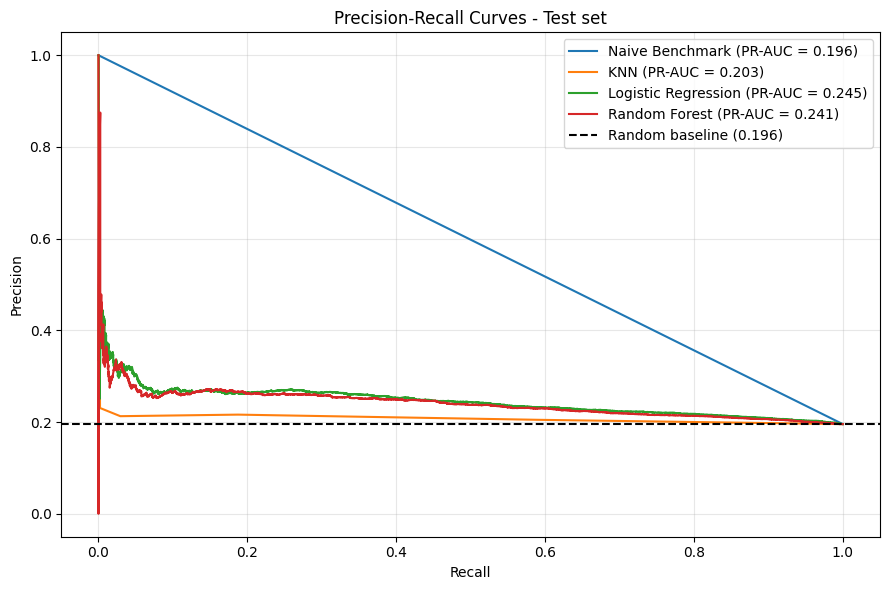

In [ ]:
plt.figure(figsize=(9,6))
for name, y_scores in scores.items():
    precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
    pr_auc = average_precision_score(y_test, y_scores)
    plt.plot(recall, precision, label=f"{name} (PR-AUC = {pr_auc:.3f})")

# Baseline: prevalence of the spoiled class
baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    color="black",
    label=f"Random baseline ({baseline:.3f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Test set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The PR Curve on test set shows that Logistic Regression achieved the highest PR-AUC followed closely by Random Forest. The Naive Benchmark is used as the random baseline to compare the models. Both the models performed better than kNN but their relatively low scores indicate difficulty identifying the spoiled products.

### **Confusion Matrix for the Test Set**

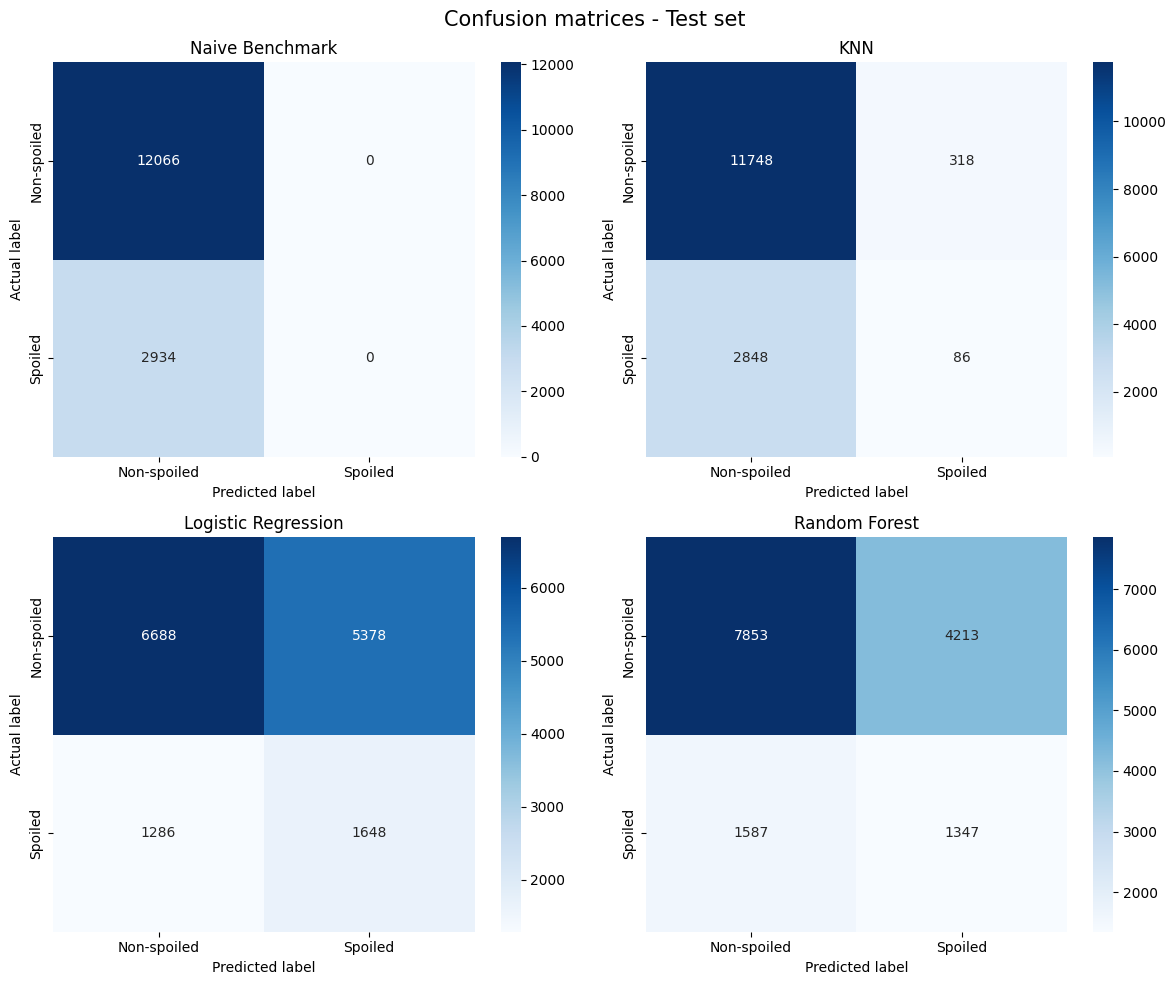

In [ ]:
# Printing the confusion matric for the test set
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-spoiled", "Spoiled"],
        yticklabels=["Non-spoiled", "Spoiled"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.suptitle("Confusion matrices - Test set", fontsize=15)
plt.tight_layout()
plt.show()

The confusion matrices of all the models represent that Logistic Regression identified the most spoiled products (1648), followed by Random Forest (1347), while kNN identified only 86 and the naive benchmark identified none. However, the Logistic Regression model also produced the highest false positives (5378) than Random Forest (4213), showing a trade off between detecting spoilage and generating false alarms.

### **ROC Curve for Test Set**


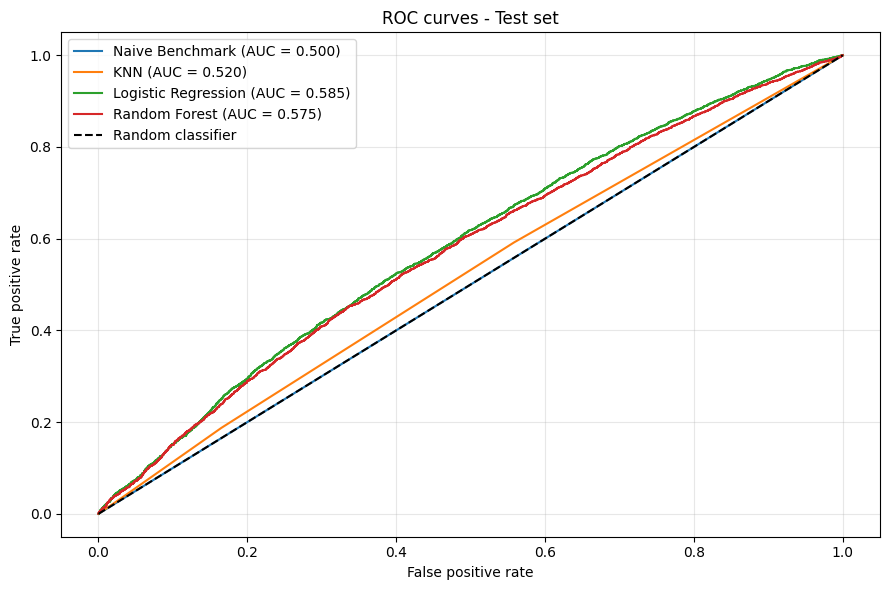

In [ ]:
plt.figure(figsize=(9, 6))
for name, y_scores in scores.items():
    fpr, tpr, thresholds = roc_curve(y_test, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Random classifier"
)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves - Test set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The ROC Curve depicts that Logistic Regression achieved the highest ROC-AUC (0.585), followed very closely by Random Forest (0.575), better than kNN (0.520). It shows that Logistic Regression and Random Forest distinguish spoiled from non-spoiled items slightly better than the random classifier.

### **Feature Importance for Logistic Regression and Random Forest**

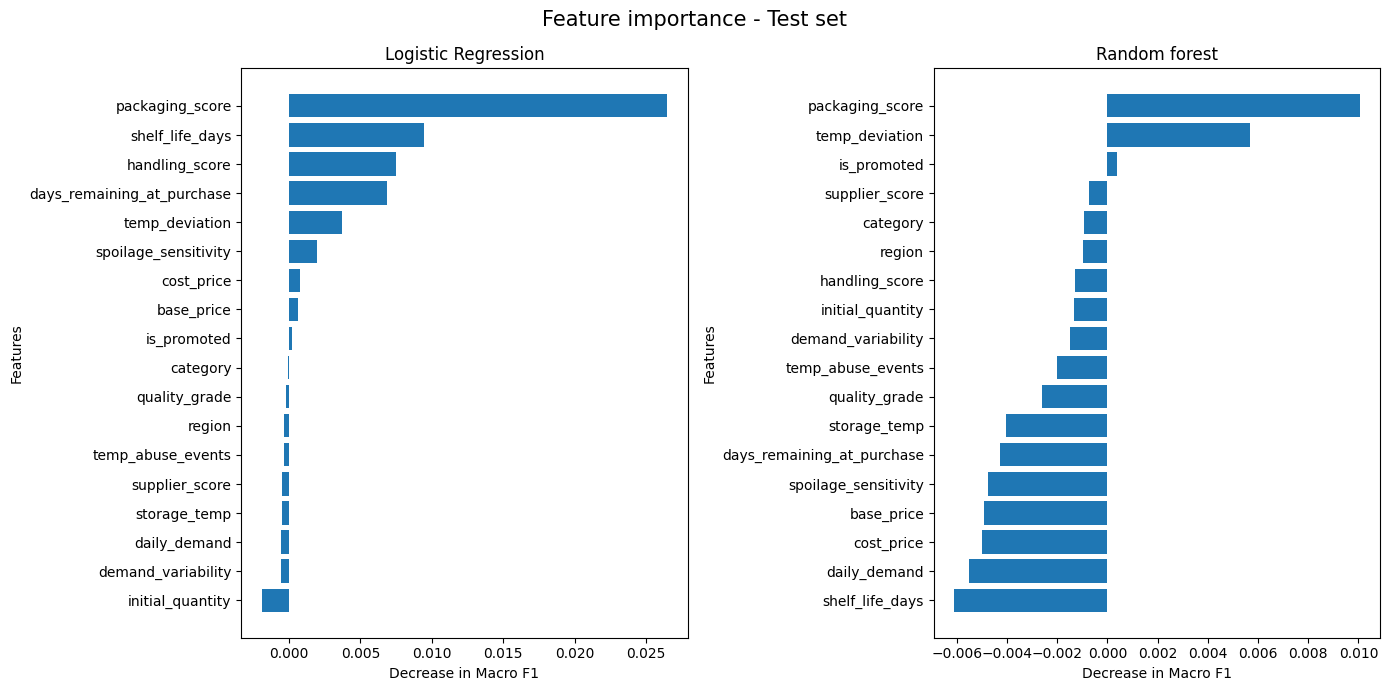

In [ ]:
# Models and their corresponding test features
feature_models = {
    "Logistic Regression": (lr_model, X_test_scaled),
    "Random forest": (clf, X_test)
}
fig, axes = plt.subplots(1, 2, figsize=(14,7))
for ax, (name, (model, X_data)) in zip(axes, feature_models.items()):
    result = permutation_importance(
        model,
        X_data,
        y_test,
        scoring="f1_macro",
        n_repeats=10,
        random_state=42
    )
    importance = pd.Series(result.importances_mean, index=X_data.columns).sort_values(ascending=True)
    ax.barh(importance.index, importance.values)
    ax.set_title(name)
    ax.set_xlabel("Decrease in Macro F1")
    ax.set_ylabel("Features")

plt.suptitle("Feature importance - Test set", fontsize=15)
plt.tight_layout()
plt.show()

This figure shows that for Logistic Regression, `packaging_score`, `shelf_life_days`, `handling_score` and `days_remaining_at_purchase` were the most important features. For Random Forest, `packaging_score` and `temp_deviation` represented the strongest positive importance, while several features had negative importance, suggesting that they did not improve the model's Macro F1 score (primary evaluation metric) on the test set.

## **<ins>Error Analysis</ins>**

The test results show that on unknown data all four models made prediction errors, especially in identifying the spoiled items. The confusion matrices of all the models provide the most useful visualisation for examining model performance. The naive benchmark predicted all items as non-spoiled based on the majority class, making it inefficient. kNN also performed poorly by identifying only 86 spoiled items while missing 2848 spoiled items. This represents that both models struggle to identify the minority class and are ineffective at detecting spoilage.

Logistic Regression performed better by correctly predicting 1648 spoiled items and missing 1286. However, it also misclassified 5378 non spoiled items as spoiled. Random Forest correctly identified 1347 spoiled items and missed 1587. The Random Forest produced fewer false positives of about 4213 than Logistic Regression. These results highlight the trade-off between detecting spoiled items and incorrectly flagging non-spoiled items.

False negatives are particularly important because they show items that are actually spoiled but the model predicted as non-spoiled. This can lead to increased inventory waste in grocery stores in real life as the stores might not be able to take action on those items, as these items remain in the inventory. Moreover, false positives are also concerning as they represent that an item is predicted to be spoiled but it is actually non-spoiled. This could lead to unnecessary discounts or the removal of items from grocery stores that are perfectly good resulting in avoidable financial losses for the store.

The PR (precision-recall) curve provides further insight into the ability of the models to identify spoiled items. Precision measures the proportion of predicted spoiled items that are actually spoiled, while recall measures the proportion of all spoiled items that are correctly identified by the models. Since identifying spoiled items is essential for reducing inventory waste, both recall and precision are important metrics to consider in order to avoid real world problems. The ROC curve measures the models' ability to distinguish between the spoiled and non-spoiled classes. The relatively low ROC-AUC and PR-AUC scores indicate that the models still have difficulty in distinguishing between spoiled and non-spoiled items. The feature importance suggests that some of the available features may not provide enough information for accurate spoilage predictions.

Overall, Logistic Regression was most effective at maximizing spoiled-class recall, while Random Forest achieved the highest Macro F1 and provided the best balance between spoiled and non-spoiled classifications. Although Logistic Regression produces false alarms, it demonstrated a better ability to distinguish between spoiled and non-spoiled items and achieved the highest PR-AUC and ROC-AUC values. Nevertheless, further improvements would be required before implementing the model in a real grocery store environment.

## **<ins>Uncertainty</ins>**

### **Bootstrap Confidence Interval for PR-AUC**


In [ ]:

import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import average_precision_score

# Train kNN for bootstrap analysis
knn_bootstrap_model = KNeighborsClassifier(n_neighbors=4)
knn_bootstrap_model.fit(X_train_scaled, y_train)

# Get validation probabilities
knn_bootstrap_y_true = np.array(y_val)
knn_bootstrap_y_prob = knn_bootstrap_model.predict_proba(
    X_val_scaled
)[:, 1]

# Bootstrap settings
knn_bootstrap_rng = np.random.default_rng(42)
knn_bootstrap_iterations = 1000
knn_bootstrap_scores = []

for i in range(knn_bootstrap_iterations):

    knn_bootstrap_indices = knn_bootstrap_rng.choice(
        len(knn_bootstrap_y_true),
        size=len(knn_bootstrap_y_true),
        replace=True
    )

    knn_bootstrap_y_sample = knn_bootstrap_y_true[
        knn_bootstrap_indices
    ]

    knn_bootstrap_prob_sample = knn_bootstrap_y_prob[
        knn_bootstrap_indices
    ]

    # Skip samples containing only one class
    if len(np.unique(knn_bootstrap_y_sample)) < 2:
        continue

    knn_bootstrap_score = average_precision_score(
        knn_bootstrap_y_sample,
        knn_bootstrap_prob_sample
    )

    knn_bootstrap_scores.append(knn_bootstrap_score)


# Calculate confidence interval
if len(knn_bootstrap_scores) > 0:

    knn_bootstrap_lower = np.percentile(
        knn_bootstrap_scores, 2.5
    )

    knn_bootstrap_upper = np.percentile(
        knn_bootstrap_scores, 97.5
    )

    knn_bootstrap_original = average_precision_score(
        knn_bootstrap_y_true,
        knn_bootstrap_y_prob
    )

    print(f"Original Validation PR-AUC: {knn_bootstrap_original:.4f}")
    print(f"Bootstrap Samples Attempted: {knn_bootstrap_iterations}")
    print(f"Valid Bootstrap Samples: {len(knn_bootstrap_scores)}")
    print(
        f"95% Bootstrap Confidence Interval: "
        f"({knn_bootstrap_lower:.4f}, {knn_bootstrap_upper:.4f})"
    )

else:
    print("Unable to calculate bootstrap confidence interval.")


Original Validation PR-AUC: 0.2013
Bootstrap Samples Attempted: 1000
Valid Bootstrap Samples: 1000
95% Bootstrap Confidence Interval: (0.1942, 0.2092)


Bootstrap sampling was used to estimate uncertainty in the kNN model's validation PR-AUC. A total of 1,000 bootstrap samples were attempted by sampling validation observations with replacement. Samples containing only one class were excluded because PR-AUC requires both classes. The 2.5th and 97.5th percentiles were used to calculate a 95% confidence interval. The resulting confidence interval was 0.1942 to 0.2092. This interval estimates how much the validation PR-AUC may vary due to sampling uncertainty. However, it does not guarantee that the model will achieve the same performance on future data.

The bootstrap assumes that validation observations are independent, even though transactions may have time-related patterns. Therefore, the confidence interval may not fully capture uncertainty related to changes over time.

### **Feature Selection Uncertainty**

The selection of features introduces uncertainty because some columns were removed due to potential data leakage. Although class mean comparisons helped identify differences between spoiled and non-spoiled products, they cannot determine whether a feature is safe to use for prediction. The main consideration is whether the information would be available when the prediction is made. For example, features such as `units_wasted`, `waste_cost`, and `profit` describe outcomes that occur after spoilage and should remain excluded. Other features should be reviewed based on their definitions and availability at prediction time. This means that the final model's performance may depend on which features are considered appropriate for use.

These feature selection decisions can affect all three models because each model relies on the available input features to make predictions. Therefore, changes in the selected features may lead to different performance results across kNN, Logistic Regression, and Random Forest.

### **Limitations of the Evaluation**

The sensitivity, robustness, and ablation experiments were conducted using only the kNN baseline. Therefore, the results may not apply to Logistic Regression and Random Forest. Although all three models were included in the overall model comparison, further experiments using the same sensitivity and ablation methods on the other models would help determine whether similar patterns occur. The use of a synthetic dataset and the chronological nature of the data are also limitations when interpreting the evaluation results.

## **<ins>Sensitivity/Robustness/Ablation</ins>**


### **Feature Ablation**

   
Ablation means removing selected features and comparing the results against the original model.

In [ ]:

import pandas as pd


from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)

# Features related to storage and product handling
knn_ablation_handling_cols = [
    'storage_temp',
    'temp_deviation',
    'temp_abuse_events',
    'handling_score',
    'packaging_score'
]

# Keep only columns that exist in the current feature set
knn_ablation_handling_cols = [
    col for col in knn_ablation_handling_cols
    if col in X_train_scaled.columns
]

print("Features selected for removal:", knn_ablation_handling_cols)


# Function to train and evaluate kNN
def evaluate_knn_ablation(X_train_exp, X_val_exp, experiment):

    model = KNeighborsClassifier(n_neighbors=4)
    model.fit(X_train_exp, y_train)

    predictions = model.predict(X_val_exp)
    probabilities = model.predict_proba(X_val_exp)[:, 1]

    return {
        "Experiment": experiment,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average='macro'),
        "Spoiled Precision": precision_score(
            y_val, predictions, pos_label=1, zero_division=0
        ),
        "Spoiled Recall": recall_score(
            y_val, predictions, pos_label=1, zero_division=0
        ),
        "PR-AUC": average_precision_score(y_val, probabilities)
    }


if len(knn_ablation_handling_cols) == 0:

    print("No storage/handling features were found. Ablation experiment skipped.")

else:

    # Experiment 1: use all approved features
    knn_ablation_full_result = evaluate_knn_ablation(
        X_train_scaled,
        X_val_scaled,
        "All features"
    )

    # Experiment 2: remove storage and handling features
    knn_ablation_X_train_reduced = X_train_scaled.drop(
        columns=knn_ablation_handling_cols
    )

    knn_ablation_X_val_reduced = X_val_scaled.drop(
        columns=knn_ablation_handling_cols
    )

    knn_ablation_reduced_result = evaluate_knn_ablation(
        knn_ablation_X_train_reduced,
        knn_ablation_X_val_reduced,
        "Without storage/handling features"
    )

    # Display comparison
    knn_ablation_results = pd.DataFrame([
        knn_ablation_full_result,
        knn_ablation_reduced_result
    ])

    display(knn_ablation_results.round(4))


Features selected for removal: ['storage_temp', 'temp_deviation', 'temp_abuse_events', 'handling_score', 'packaging_score']


,Experiment,Accuracy,Macro F1,Spoiled Precision,Spoiled Recall,PR-AUC
0,All features,0.7858,0.4650,0.2072,0.0290,0.2013
1,Without storage/handling features,0.7873,0.4654,0.2174,0.0286,0.1987


The feature ablation experiment examined whether storage and product handling features contributed to the kNN model's performance. The full feature set was compared with a reduced feature set after removing five storage and handling-related features. Removing these features slightly increased accuracy from 0.7858 to 0.7873 and Macro F1 from 0.4650 to 0.4654. Spoiled-class precision also increased from 0.2072 to 0.2174. However, spoiled-class recall decreased slightly from 0.0290 to 0.0286, and PR-AUC decreased from 0.2013 to 0.1987. Overall, the changes in performance were very small. The decreases in recall and PR-AUC suggest that the removed features may provide some useful information for identifying spoiled products. However, this experiment does not show a major improvement from removing them.

### **Threshold Sensitivity**


,Threshold,Accuracy,Macro F1,Spoiled Recall,Spoiled Precision,PR-AUC
0,0.3,0.7007,0.5052,0.1822,0.2079,0.2013
1,0.4,0.7007,0.5052,0.1822,0.2079,0.2013
2,0.5,0.7007,0.5052,0.1822,0.2079,0.2013
3,0.6,0.7858,0.4650,0.0290,0.2072,0.2013


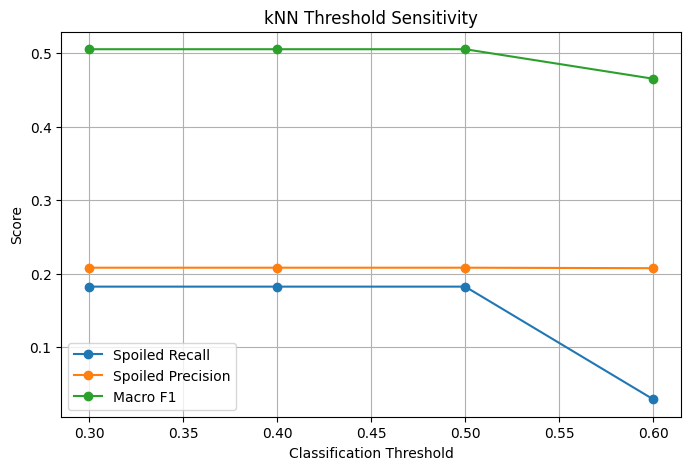

In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)

# Threshold Sensitivity Analysis for kNN

knn_threshold_model = KNeighborsClassifier(n_neighbors=4)
knn_threshold_model.fit(X_train_scaled, y_train)

# Get kNN probabilities
knn_threshold_y_scores = knn_threshold_model.predict_proba(
    X_val_scaled
)[:, 1]

knn_thresholds = [0.30, 0.40, 0.50, 0.60]
knn_threshold_results = []

# Calculate PR-AUC once because it does not depend on the threshold
knn_threshold_pr_auc = average_precision_score(
    y_val, knn_threshold_y_scores
)

for threshold in knn_thresholds:

    # Convert probabilities into class predictions
    knn_threshold_predictions = (
        knn_threshold_y_scores >= threshold
    ).astype(int)

    knn_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val, knn_threshold_predictions
        ),
        "Macro F1": f1_score(
            y_val, knn_threshold_predictions, average='macro'
        ),
        "Spoiled Recall": recall_score(
            y_val, knn_threshold_predictions,
            pos_label=1, zero_division=0
        ),
        "Spoiled Precision": precision_score(
            y_val, knn_threshold_predictions,
            pos_label=1, zero_division=0
        ),
        "PR-AUC": knn_threshold_pr_auc
    })

knn_threshold_df = pd.DataFrame(knn_threshold_results)

display(knn_threshold_df.round(4))


# Plot threshold sensitivity
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    knn_threshold_df["Threshold"],
    knn_threshold_df["Spoiled Recall"],
    marker='o',
    label='Spoiled Recall'
)

plt.plot(
    knn_threshold_df["Threshold"],
    knn_threshold_df["Spoiled Precision"],
    marker='o',
    label='Spoiled Precision'
)

plt.plot(
    knn_threshold_df["Threshold"],
    knn_threshold_df["Macro F1"],
    marker='o',
    label='Macro F1'
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("kNN Threshold Sensitivity")
plt.legend()
plt.grid(True)
plt.show()


The threshold sensitivity experiment examined how different classification thresholds affected the kNN model's ability to identify spoiled products. At thresholds of 0.30, 0.40, and 0.50, the evaluation metrics remained the same. However, increasing the threshold to 0.60 increased accuracy to 0.7858 while reducing spoiled-class recall from 0.1822 to 0.0290. Macro F1 also decreased from 0.5052 to 0.4650. PR-AUC remained unchanged because it evaluates the model's probability rankings across different thresholds rather than predictions at one specific threshold. These results show that increasing the threshold made the model more conservative when predicting spoilage, but also caused it to miss more spoiled products.

The repeated results across the first three thresholds are related to the kNN model using four neighbours. Its predicted probabilities occur in increments of 0.25, so thresholds of 0.30, 0.40, and 0.50 produced the same classifications.

### **Robustness Across Different k Values**

,k,Macro F1,Recall (spoiled=1),PR-AUC
0,1,0.4999,0.1906,0.1980
1,3,0.4946,0.1040,0.2012
2,4,0.4650,0.0290,0.2013
3,5,0.4814,0.0609,0.2021
4,7,0.4682,0.0357,0.2066
5,9,0.4625,0.0249,0.2091
6,11,0.4553,0.0145,0.2136
7,13,0.4531,0.0104,0.2134
8,15,0.4481,0.0047,0.2164


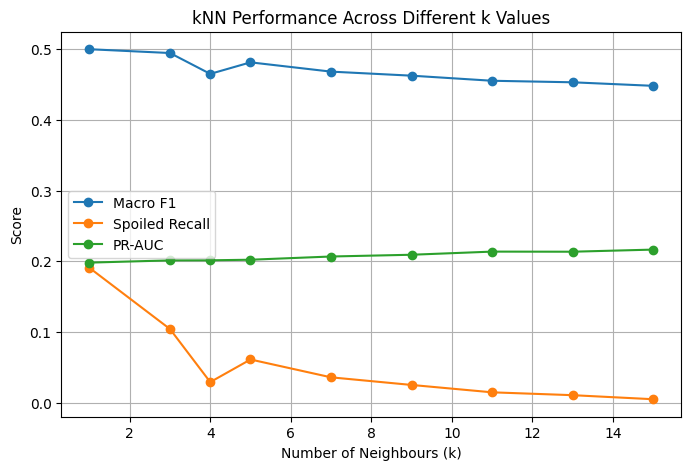

In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    f1_score,
    recall_score,
    average_precision_score
)
import pandas as pd
import matplotlib.pyplot as plt

# Checking kNN performance across different k values

knn_robustness_k_values = [1, 3, 4, 5, 7, 9, 11, 13, 15]

knn_robustness_results = []

for k in knn_robustness_k_values:

    knn_robustness_model = KNeighborsClassifier(n_neighbors=k)
    knn_robustness_model.fit(X_train_scaled, y_train)

    knn_robustness_predictions = knn_robustness_model.predict(
        X_val_scaled
    )

    knn_robustness_probabilities = (
        knn_robustness_model.predict_proba(X_val_scaled)[:, 1]
    )

    knn_robustness_results.append({
        "k": k,
        "Macro F1": f1_score(
            y_val, knn_robustness_predictions, average='macro'
        ),
        "Recall (spoiled=1)": recall_score(
            y_val, knn_robustness_predictions,
            pos_label=1, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_val, knn_robustness_probabilities
        )
    })

knn_robustness_df = pd.DataFrame(knn_robustness_results)

display(knn_robustness_df.round(4))


# Visualize kNN performance across different k values

plt.figure(figsize=(8, 5))

plt.plot(
    knn_robustness_df["k"],
    knn_robustness_df["Macro F1"],
    marker='o',
    label='Macro F1'
)

plt.plot(
    knn_robustness_df["k"],
    knn_robustness_df["Recall (spoiled=1)"],
    marker='o',
    label='Spoiled Recall'
)

plt.plot(
    knn_robustness_df["k"],
    knn_robustness_df["PR-AUC"],
    marker='o',
    label='PR-AUC'
)

plt.xlabel("Number of Neighbours (k)")
plt.ylabel("Score")
plt.title("kNN Performance Across Different k Values")
plt.legend()
plt.grid(True)
plt.show()


The robustness experiment evaluated how changing the number of neighbours affected kNN performance. The results show that Macro F1 and spoiled-class recall generally decreased as k increased, although there were some small variations. In contrast, PR-AUC generally increased, reaching its highest value of 0.2164 at k = 15. The highest Macro F1 and spoiled-class recall were achieved at k = 1.

A smaller k places more emphasis on individual neighbouring points when making predictions, which can make the model more sensitive to noise. A larger k considers more neighbours, but can make it harder to identify the minority spoiled class. We retained k = 4 as our baseline configuration for the remaining experiments. However, its low spoiled-class recall shows that it was not the strongest configuration for detecting spoiled products.

This experiment shows how changing the kNN hyperparameter affects its performance. However, it does not establish that kNN performs better than the other models. Logistic Regression and Random Forest must also be considered when comparing the overall model performance.

## **<ins>Recommendation System</ins>**

In [ ]:
# Recommends actions based on the probability of an item spoiling and how many days are left before it spoils
def recommend_action(spoil_prob, days_remaining):
    if spoil_prob >= 0.58 and days_remaining <= 3:
        return "Discount item and move to front of shelf"

    elif spoil_prob >= 0.58:
        return "Apply markdown pricing"

    elif spoil_prob >= 0.50:
        return "Monitor inventory closely"

    else:
        return "No action required"

In [62]:
# Create a DataFrame using test set features and Random Forest spoilage probabilities
recommendations_df = df_test[['category', 'region', 'days_remaining_at_purchase', 'storage_temp', 'was_spoiled']].copy()
recommendations_df['spoil_prob'] = clf.predict_proba(X_test)[:, 1].round(3)

# Apply the recommendation function row-by-row
recommendations_df['recommended_action'] = recommendations_df.apply(
    lambda row: recommend_action(row['spoil_prob'], row['days_remaining_at_purchase']),
    axis=1
)

# Show distribution of recommended actions across the test set
print("______Summary of Recommended Actions-Test Set (15,000 items)__________")
action_counts = recommendations_df['recommended_action'].value_counts()
action_percents = (recommendations_df['recommended_action'].value_counts(normalize=True) * 100).round(2)
summary_table = pd.DataFrame({'Item Count': action_counts, 'Percentage (%)': action_percents})
display(summary_table)

# 2. Show sample high-risk items with different actions
print("\n____________Sample High-risk Inventory Recommendations_______________")
high_risk_only = recommendations_df[recommendations_df['recommended_action'] != "No action required"]
high_risk_samples = pd.concat([high_risk_only.head(10), high_risk_only.tail(10)])
display(high_risk_samples)

______Summary of Recommended Actions-Test Set (15,000 items)__________


,Item Count,Percentage (%)
recommended_action,,
No action required,9401,62.67
Monitor inventory closely,4815,32.10
Apply markdown pricing,590,3.93
Discount item and move to front of shelf,194,1.29



____________Sample High-risk Inventory Recommendations_______________


,category,region,days_remaining_at_purchase,storage_temp,was_spoiled,spoil_prob,recommended_action
84593,8,4,3,3.2,0,0.541,Monitor inventory closely
31124,7,2,6,7.4,0,0.515,Monitor inventory closely
7229,9,0,2,1.3,0,0.505,Monitor inventory closely
39876,6,1,189,7.2,0,0.533,Monitor inventory closely
95468,6,3,552,7.3,0,0.503,Monitor inventory closely
62574,8,0,4,2.5,1,0.556,Monitor inventory closely
59344,8,0,4,6.5,0,0.549,Monitor inventory closely
29819,7,1,7,10.6,1,0.532,Monitor inventory closely
30007,5,4,6,0.3,0,0.539,Monitor inventory closely
15369,6,4,82,2.6,0,0.607,Apply markdown pricing


The recommendation system uses the Random Forest model’s spoilage probabilities and remaining shelf life to recommend actions such as moving items to the front of shelves, discounting items, monitor closely, or no action required. This helps grocery stores with knowing which items require action and what action to take to prevent the wastage of perishable items. More testing would be required before being implemented for an grocery store.

## **<ins>Experiment Log</ins>**

### **Logistic Regression**

| Experiment | Model | Hyperparameters | Validation Accuracy | Validation Macro F1 | Validation PR-AUC | Notes |
|---|---|---|:---:|:---:|:---:|---|
| Logistic Regression-1 | Logistic Regression | class_weight=None, C=1.0 | 0.802000 | 0.445061 | 0.258993 | Predicted mostly the majority class and failed to detect spoiled products |
| Logistic Regression-2 | Logistic Regression | class_weight=None, C=5.0 | 0.802000 | 0.445061 | 0.259003 | Increasing C (Regularization) had no effect, still predicting majority class |
| Logistic Regression-3 | Logistic Regression | class_weight=None, C=10.0 | 0.802000 | 0.445061 | 0.259003 | Increasing C (Regularization) had no effect, still predicting majority class |
| Logistic Regression-4 | Logistic Regression | class_weight=None, C=20.0 | 0.802000 | 0.445061 | 0.259001 | Increasing C (Regularization) had no effect, still predicting majority class |
| Logistic Regression-5 | Logistic Regression | class_weight='balanced', C=1.0 | 0.563733 | 0.506557 | 0.258905 | Using class_weight='balanced' changed results dramatically. <br> An increase in Macro F1 and a decrease in Accuracy indicate that the model is <br> actually learning and predicting patterns now instead of predicting the majority class |
| Logistic Regression-6 | Logistic Regression | class_weight='balanced', C=5.0 | 0.563800 | 0.506658 | 0.258908 | Increasing C (Regularization) slightly improved the metrics |
| Logistic Regression-7 | Logistic Regression | class_weight='balanced', C=10.0 | 0.563800 | 0.506658 | 0.258912 | Increasing C (Regularization) made no difference on Accuracy and Macro F1 but had a <br> slight increase in PR-AUC. This model also had the best results, selected as final model  |
| Logistic Regression-8 | Logistic Regression | class_weight='balanced', C=20.0 | 0.563800 | 0.506658 | 0.258912 | Increasing C (Regularization) made no difference on any metrics, model stagnated |

Four `C` (Regularization) values were tested, each with `class_weight=None` and `class_weight='balanced'`. Using any C value with `class_weight=None` had no effect on the results, as the model mostly predicted the majority class and failed to detect any spoiled products. Using `class_weight='balanced'` allowed the model to start learning patterns and predicting spoiled products, and increasing the C value showed improvements in Accuracy, PR-AUC, and Macro F1. However, the metrics stopped improving after `C=10.0`, so we chose `C=10.0` with `class_weight='balanced'` as the final Logistic Regression model.

### **Random Forest**

| Experiment | Model | Hyperparameters | Training Macro F1 | Validation Accuracy | Validation Macro F1 | Notes |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Random Forest-1** | Random Forest | `n_estimators=100`, `max_depth=None`, `class_weight=None` | 1.0000 | 0.801667 | 0.446943 | The training set achieved high performance<br>but has a lower validation Macro F1,<br>suggesting overfitting. |
| **Random Forest-2** | Random Forest | `n_estimators=100`, `max_depth=None`, `class_weight='balanced'` | 1.0000 | 0.802200 | 0.446451 | Balanced class weights didn't improve<br>validation Macro F1 even though it had<br>perfect training performance. |
| **Random Forest-3** | Random Forest | `n_estimators=200`,`max_depth=None`,`class_weight='balanced'` | 1.0000 | 0.801933 | 0.446036 | Increasing the number of trees to 200<br>didn't improve validation Macro F1 and<br>it didn't really change the gap between<br>the training and validation Macro F1 scores. |
| **Random Forest-4** | Random Forest | `n_estimators=200`, `max_depth=20`, `class_weight='balanced'` | 0.9978 | 0.797933 | 0.457421 | Limiting tree depth to 20 slightly improved<br>validation Macro F1, but the training<br>performance is alsmost perfect. |
| **Random Forest-5** | Random Forest | `n_estimators=200`, `max_depth=10`, `class_weight='balanced'` | 0.6097 | 0.622000 | 0.531114 | Limiting tree depth to 10 produced the<br>highest validation Macro F1 and a smaller<br>gap between the training and validation<br>Macro F1 scores. Selected as the final<br>configuration. |

Five Random Forest configurations were tested by varying the number of trees, maximum tree depth, and class weighting strategy. The first four configurations achieved very high training Macro F1 scores but lower validation scores, suggesting overfitting. Adding balanced class weights and increasing the number of trees did not really improve validation performance. Limiting the maximum tree depth to 20 produced a little improvement, while reducing it to 10 resulted in the highest validation Macro F1 of 0.5311 and a smaller gap between training and validation performance. Therefore, Random Forest-5 was selected as the final configuration.

### **kNN**

| Experiment | Model | Hyperparameters | Validation Macro F1 | Validation Spoiled Recall | Validation PR-AUC | Notes |
|:---|:---|:---|:---|:---|:---|:---|
| **kNN-1** | kNN | `n_neighbors=1` | 0.4999 | 0.1906 | 0.1980 | Achieved the highest Macro F1 and spoiled-class recall among the tested k values. |
| **kNN-2** | kNN | `n_neighbors=3` | 0.4946 | 0.1040 | 0.2012 | Macro F1 remained relatively high, but spoiled-class recall decreased compared with k=1. |
| **kNN-3** | kNN | `n_neighbors=4` | 0.4650 | 0.0290 | 0.2013 | Retained as the baseline configuration, although it had very low spoiled-class recall. |
| **kNN-4** | kNN | `n_neighbors=5` | 0.4814 | 0.0609 | 0.2021 | Increasing k to 5 improved recall compared with k=4, but it remained low. |
| **kNN-5** | kNN | `n_neighbors=7` | 0.4682 | 0.0357 | 0.2066 | Macro F1 and recall decreased, while PR-AUC improved. |
| **kNN-6** | kNN | `n_neighbors=9` | 0.4625 | 0.0249 | 0.2091 | Spoiled-class recall continued to decrease as k increased. |
| **kNN-7** | kNN | `n_neighbors=11` | 0.4553 | 0.0145 | 0.2136 | PR-AUC improved, but the model detected fewer spoiled products. |
| **kNN-8** | kNN | `n_neighbors=13` | 0.4531 | 0.0104 | 0.2134 | Macro F1 and recall remained low, with a small decrease in PR-AUC compared with k=11. |
| **kNN-9** | kNN | `n_neighbors=15` | 0.4481 | 0.0047 | 0.2164 | Achieved the highest PR-AUC, but had the lowest Macro F1 and spoiled-class recall. |



Nine kNN configurations were tested by varying the number of neighbors (`n_neighbors`) from 1 to 15. Increasing `n_neighbors` slowly improved validation PR-AUC with `n_neighbors=15` (PR_AUC: 0.2164), but it caused a drop in Macro F1 and spoiled-class recall as the model favored the majority class. Smaller neighbor counts (`n_neighbors=1`) achieved the highest Macro F1 (0.4999) and spoiled-class recall (0.1906). `n_neighbors=4` (kNN-3) was used as the baseline configuration despite its low recall (0.0290) to serve as the reference point for subsequent threshold tuning and ablation experiments.

### **Additional kNN Experiments (`n_neighbors=4`)**

| Experiment | Configuration | Accuracy | Macro F1 | Spoiled Precision | Spoiled Recall | PR-AUC | Notes |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| **Feature Ablation-1** | All features | 0.7858 | 0.4650 | 0.2072 | 0.0290 | 0.2013 | Used as the original feature-set baseline for comparison. |
| **Feature Ablation-2** | Removed 5 storage/handling features | 0.7873 | 0.4654 | 0.2174 | 0.0286 | 0.1987 | Removing the five features caused only small changes and did not substantially improve performance. |
| **Threshold-1** | Threshold = `0.30` | 0.7007 | 0.5052 | 0.2079 | 0.1822 | 0.2013 | Lower threshold increased the number of spoiled products identified compared with the baseline threshold. |
| **Threshold-2** | Threshold = `0.40` | 0.7007 | 0.5052 | 0.2079 | 0.1822 | 0.2013 | Produced the same predictions and metrics as the `0.30` threshold. |
| **Threshold-3** | Threshold = `0.50` | 0.7007 | 0.5052 | 0.2079 | 0.1822 | 0.2013 | Produced the same predictions and metrics as the `0.30` and `0.40` thresholds. |
| **Threshold-4** | Threshold = `0.60` | 0.7858 | 0.4650 | 0.2072 | 0.0290 | **0.2013** | Higher threshold increased accuracy but reduced spoiled-class recall and Macro F1. |
| **Bootstrap-1** | 1,000 bootstrap samples; 95% CI; `random_state=42` | - | - | - | - | 0.2013 | **95% CI: (0.1942, 0.2092)**. All 1,000 bootstrap samples were valid; estimates uncertainty in validation PR-AUC. |

Removed features: `storage_temp`, `temp_deviation`, `temp_abuse_events`, `handling_score`, and `packaging_score`.

The kNN experiments used the validation set. Accuracy and spoiled precision are included only where those values were recorded in the experiment results. The kNN experiments tested different numbers of neighbours, feature sets, and classification thresholds to understand how these choices affected model performance. The results showed that smaller k values generally achieved higher Macro F1 and spoiled-class recall, while larger k values achieved higher PR-AUC. The feature ablation experiment showed that removing the five storage and handling features caused only small changes in performance. The threshold experiment also showed that lowering the classification threshold increased spoiled-class recall, although accuracy decreased. Finally, bootstrap sampling was used to estimate uncertainty in the validation PR-AUC, producing a 95% confidence interval from 0.1942 to 0.2092. Overall, these experiments showed that kNN's performance was sensitive to its settings, but its ability to identify spoiled products remained limited.

### **Experiment Reproducibility**

#### **Software**

In [ ]:
import sys
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import seaborn as sns

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
pandas: 2.2.3
NumPy: 2.4.6
scikit-learn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2


#### **Hardware**
- Experiments were executed using Google Colab

#### **Data Split**
- Training set: 70%
- Validation set: 15%
- Test set: 15%
- Time-based split using transaction_date

#### **Random Seeds**
- random_state = 42 was used for Logistic Regression, Random Forest, and feature importance
- np.random.default_rng(42) was used for bootstrap sampling

#### **Preprocessing**
- Unecessary columns removed
- Leakage-prone features were removed
- Transaction dates converted to datetime format
- Label encoding fitted only on the training set
- StandardScaler fitted on the training set and applied to validation and test sets
- Random Forest used unscaled features
- kNN and Logistic Regression used scaled numeric features

#### **Notes**
- All models used the same train, validation, and test splits
- Hyperparameter tuning was performed only on the validation set
- The test set was used once for final evaluation after model selection.
- Training and prediction times were measured on a Google Colab CPU runtime and may vary between executions.

## **<ins>Conclusion and Limitations</ins>**

#### **Conclusion**
Random Forest achieved the highest Macro F1 on both the validation set (0.5311) and test set (0.5237). Logistic Regression achieved the second-highest Macro F1 (0.5067 validation, 0.4992 test) and the highest spoiled-class recall and PR-AUC. kNN has a Macro F1 of 0.4650 for validation and 0.4664 for test, while the Naive Benchmark has 0.4451 for validation and 0.4458 for test. Logistic Regression and Random Forest detect far more spoiled items than kNN. The two models are almost tied on PR-AUC. kNN’s PR-AUC confidence interval (0.1942 to 0.2092) contains the spoiled rate (0.198), so we cannot separate it from chance. No model meets the Milestone 2 targets (Macro F1 > 0.65, recall > 0.70, PR-AUC > 0.35).



#### **Limitations**
**(1)** Only one synthetic dataset was used, so results may not carry over to real grocery stores or future periods. **(2)** Results come from one time-based split and one seed per model, and bootstrap intervals exist only for kNN so we cannot say whether the gap between Logistic Regression and the Random Forest exceeds sampling noise. **(3)** Precision stays low so most flagged items are false alarms. **(4)** The sensitivity and ablation analyses used only kNN, and the retained feature set depends on decisions about which columns leak information that we have not yet verified.

## **<ins>References</ins>**

**Random Forest**

https://medium.com/@parth.m1413/random-forest-explained-simply-when-why-and-how-to-use-it-in-real-projects-363d35f545b3

https://medium.com/@kalpit.sharma/mastering-random-forest-hyperparameter-tuning-for-enhanced-machine-learning-models-2d1a8c6c426f

**Figures and error analysis**

https://mljourney.com/evaluating-ml-models-visually-confusion-matrix-roc-and-pr-curves/

https://www.geeksforgeeks.org/machine-learning/precision-recall-curve-ml/

**Bootstrap Uncertainty**

https://towardsdatascience.com/the-statistical-magic-behind-the-bootstrap-2188ee147423/?gi=67177e8ed6df